# imports

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt

In [2]:
# file imports

data_ptk1 = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\results\data_evaluation_nocat_cycle_150°C_1barabs_reactor250mlmin_matrix250mlmin.npz", allow_pickle=True)
data_ptk2 = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\results\data_evaluation_nocat_cycle_150°C_1barabs_reactor125mlmin_matrix250mlmin.npz", allow_pickle=True)
data_ptk3 = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\results\data_evaluation_nocat_cycle_150°C_1barabs_reactor250mlmin_matrix125mlmin.npz", allow_pickle=True)
data_ptk4 = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\results\data_evaluation_nocat_cycle_150°C_1barabs_reactor250mlmin_matrix0mlmin.npz", allow_pickle=True)
data_ptk5 = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\results\data_evaluation_nocat_cycle_200°C_1barabs_reactor250mlmin_matrix250mlmin.npz", allow_pickle=True)
data_ptk6 = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\results\data_evaluation_nocat_cycle_250°C_1barabs_reactor250mlmin_matrix250mlmin.npz", allow_pickle=True)
data_ptk7 = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\results\data_evaluation_nocat_cycle_300°C_1barabs_reactor250mlmin_matrix250mlmin.npz", allow_pickle=True)
data_ptk8 = np.load(r"C:\Users\admin\Nextcloud\RI Herrmann\3_Experiments\THB_V2_ges_sys_varVdot_varTemp_1barabs\results\data_evaluation_nocat_cycle_350°C_1barabs_reactor250mlmin_matrix250mlmin.npz", allow_pickle=True)


# alle PTK cycle

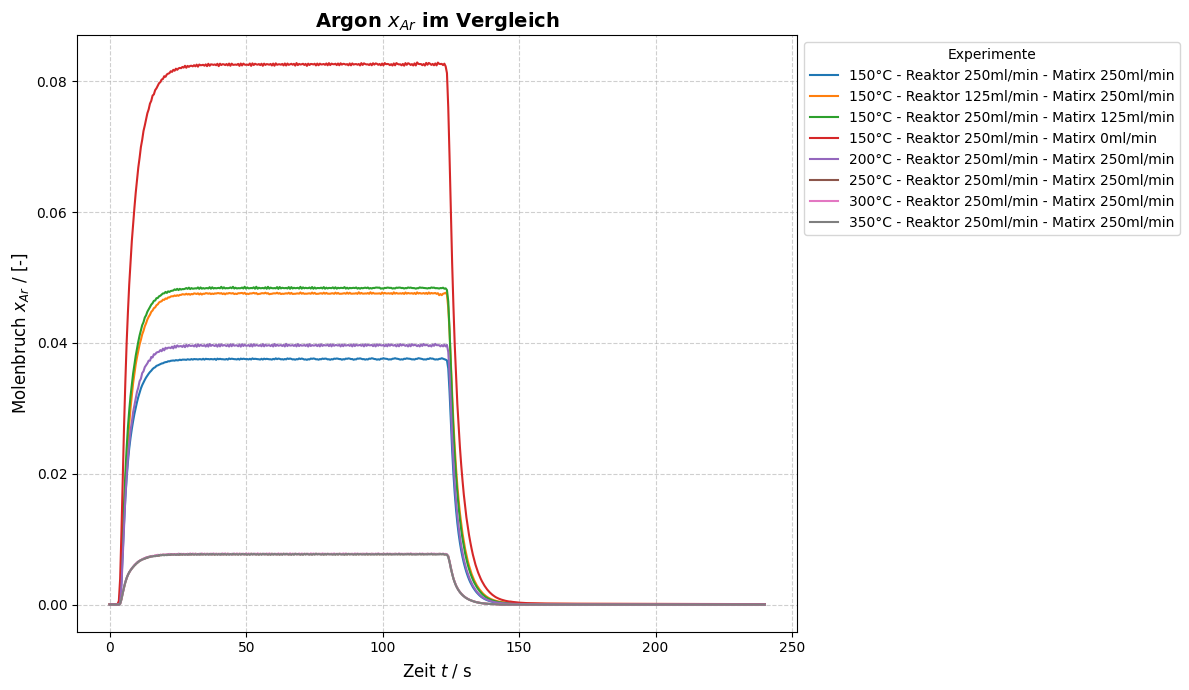

In [3]:
dataset_ptks = [
    data_ptk1, data_ptk2, data_ptk3, data_ptk4, 
    data_ptk5, data_ptk6, data_ptk7, data_ptk8
]

titles = [
    "150°C - Reaktor 250ml/min - Matirx 250ml/min", 
    "150°C - Reaktor 125ml/min - Matirx 250ml/min",
    "150°C - Reaktor 250ml/min - Matirx 125ml/min",
    "150°C - Reaktor 250ml/min - Matirx 0ml/min",
    "200°C - Reaktor 250ml/min - Matirx 250ml/min",
    "250°C - Reaktor 250ml/min - Matirx 250ml/min",
    "300°C - Reaktor 250ml/min - Matirx 250ml/min",
    "350°C - Reaktor 250ml/min - Matirx 250ml/min"
]

plt.figure(figsize=(12, 7))

for data, title  in zip(dataset_ptks, titles):
    t = data['time_delta']
    n_matrix = data['n_dot'] # alle Stoffmengenströme
    n_total = np.sum(n_matrix, axis=0)
    x_Ar = np.divide(n_matrix[0], n_total, out=np.zeros_like(n_matrix[0]), where=n_total!=0)
    
    plt.plot(t, x_Ar, label=title, linewidth=1.5)


plt.title('Argon $x_{Ar}$ im Vergleich', fontsize=14, fontweight='bold')
plt.xlabel('Zeit $t$ / s', fontsize=12)
plt.ylabel('Molenbruch $x_{Ar}$ / [-]', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), title="Experimente")

plt.tight_layout()
plt.show()

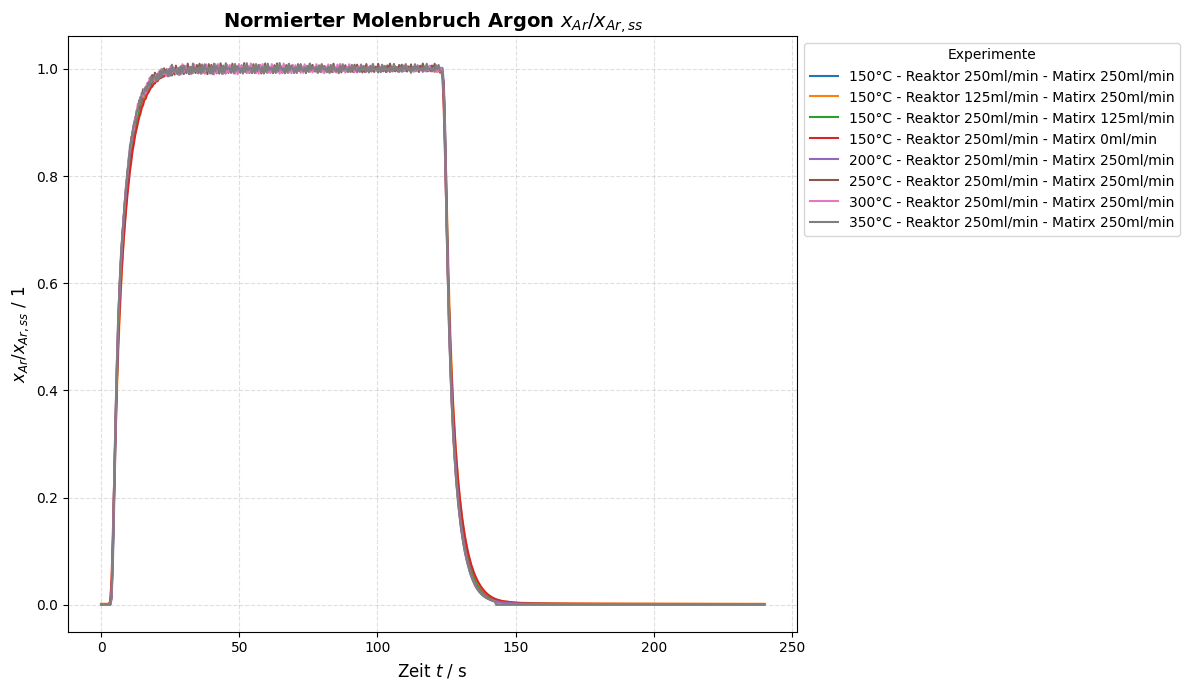

In [4]:
# alle PTKs normierte molefractions

dataset_ptks = [data_ptk1, 
                data_ptk2, 
                data_ptk3, 
                data_ptk4, 
                data_ptk5, 
                data_ptk6, 
                data_ptk7, 
                data_ptk8]

titles = [
    "150°C - Reaktor 250ml/min - Matirx 250ml/min", 
    "150°C - Reaktor 125ml/min - Matirx 250ml/min",
    "150°C - Reaktor 250ml/min - Matirx 125ml/min",
    "150°C - Reaktor 250ml/min - Matirx 0ml/min",
    "200°C - Reaktor 250ml/min - Matirx 250ml/min",
    "250°C - Reaktor 250ml/min - Matirx 250ml/min",
    "300°C - Reaktor 250ml/min - Matirx 250ml/min",
    "350°C - Reaktor 250ml/min - Matirx 250ml/min"
]

plt.figure(figsize=(12, 7))

for data, title in zip(dataset_ptks, titles):
    t = data['time_delta']
    n_matrix = data['n_dot']
    
    n_total = np.sum(n_matrix, axis=0)
    x_Ar = np.divide(n_matrix[0], n_total, out=np.zeros_like(n_matrix[0]), where=n_total!=0)
    
    mask_ss = (t >= 80) & (t <= 100)
    x_Ar_ss = np.mean(x_Ar[mask_ss])
    x_Ar_normed = x_Ar / x_Ar_ss
    
    plt.plot(t, x_Ar_normed, label=title, linewidth=1.5)

plt.title('Normierter Molenbruch Argon $x_{Ar} / x_{Ar,ss}$', fontsize=14, fontweight='bold')
plt.xlabel('Zeit $t$ / s', fontsize=12)
plt.ylabel('$x_{Ar} / x_{Ar,ss}$ / 1', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), title="Experimente")

plt.tight_layout()
plt.show()

# V_dot Variation

## gesamte V_dot Variation

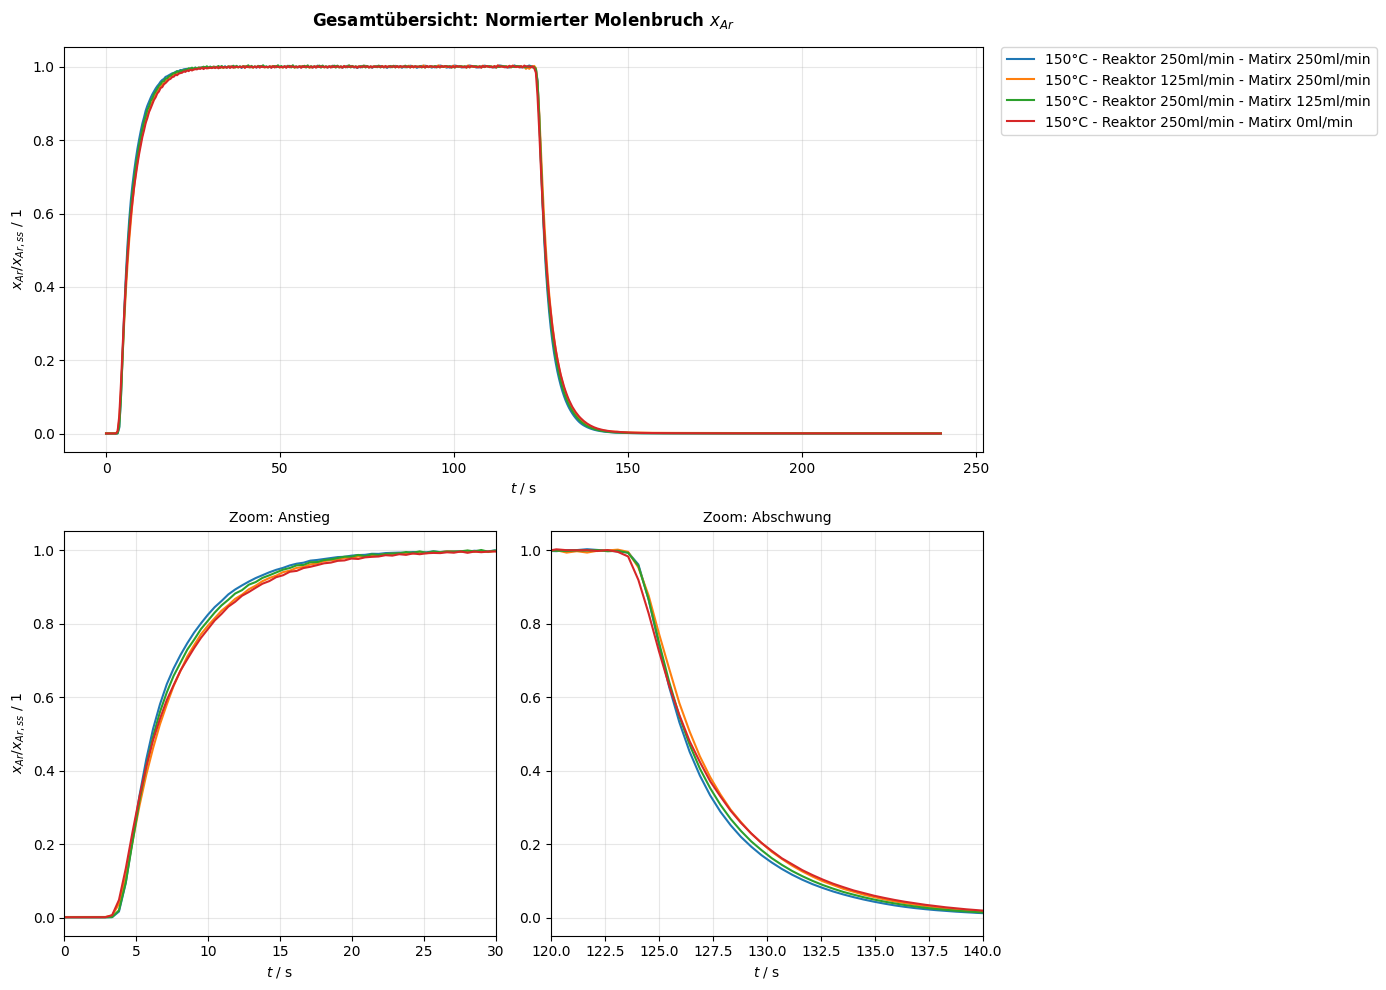

In [5]:
dataset_ptks = [data_ptk1, 
                data_ptk2, 
                data_ptk3, 
                data_ptk4
]

titles = [
    "150°C - Reaktor 250ml/min - Matirx 250ml/min", 
    "150°C - Reaktor 125ml/min - Matirx 250ml/min",
    "150°C - Reaktor 250ml/min - Matirx 125ml/min",
    "150°C - Reaktor 250ml/min - Matirx 0ml/min"
]

fig = plt.figure(figsize=(14, 10))

ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)

ax2 = plt.subplot2grid((2, 2), (1, 0)) 
ax3 = plt.subplot2grid((2, 2), (1, 1)) 


for data, title in zip(dataset_ptks, titles):
    t = data['time_delta']
    n_matrix = data['n_dot']
    
    n_total = np.sum(n_matrix, axis=0)
    x_Ar = np.divide(n_matrix[0], n_total, out=np.zeros_like(n_matrix[0]), where=n_total!=0)
    
    mask_ss = (t >= 80) & (t <= 100)
    x_Ar_ss_val = np.mean(x_Ar[mask_ss])
    x_Ar_normed = x_Ar / x_Ar_ss_val 

    ax1.plot(t, x_Ar_normed, label=title)
    ax2.plot(t, x_Ar_normed)
    ax3.plot(t, x_Ar_normed)

ax1.set_title('Gesamtübersicht: Normierter Molenbruch $x_{Ar}$', fontweight='bold', pad=15)
ax1.set_ylabel('$x_{Ar} / x_{Ar,ss}$ / 1')
ax1.set_xlabel('$t$ / s')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

ax2.set_title('Zoom: Anstieg', fontsize=10)
ax2.set_xlim(0, 30)
ax2.set_xlabel('$t$ / s')
ax2.set_ylabel('$x_{Ar} / x_{Ar,ss}$ / 1')
ax2.grid(True, alpha=0.3)

ax3.set_title('Zoom: Abschwung', fontsize=10)
ax3.set_xlim(120, 140)
ax3.set_xlabel('$t$ / s')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## V_dot Variation mit Referenz

<>:65: SyntaxWarning: invalid escape sequence '\D'
<>:65: SyntaxWarning: invalid escape sequence '\D'
C:\Users\admin\AppData\Local\Temp\ipykernel_18116\1717341080.py:65: SyntaxWarning: invalid escape sequence '\D'
  ax_diff_up.set_ylabel('$\Delta x_{Ar}$')


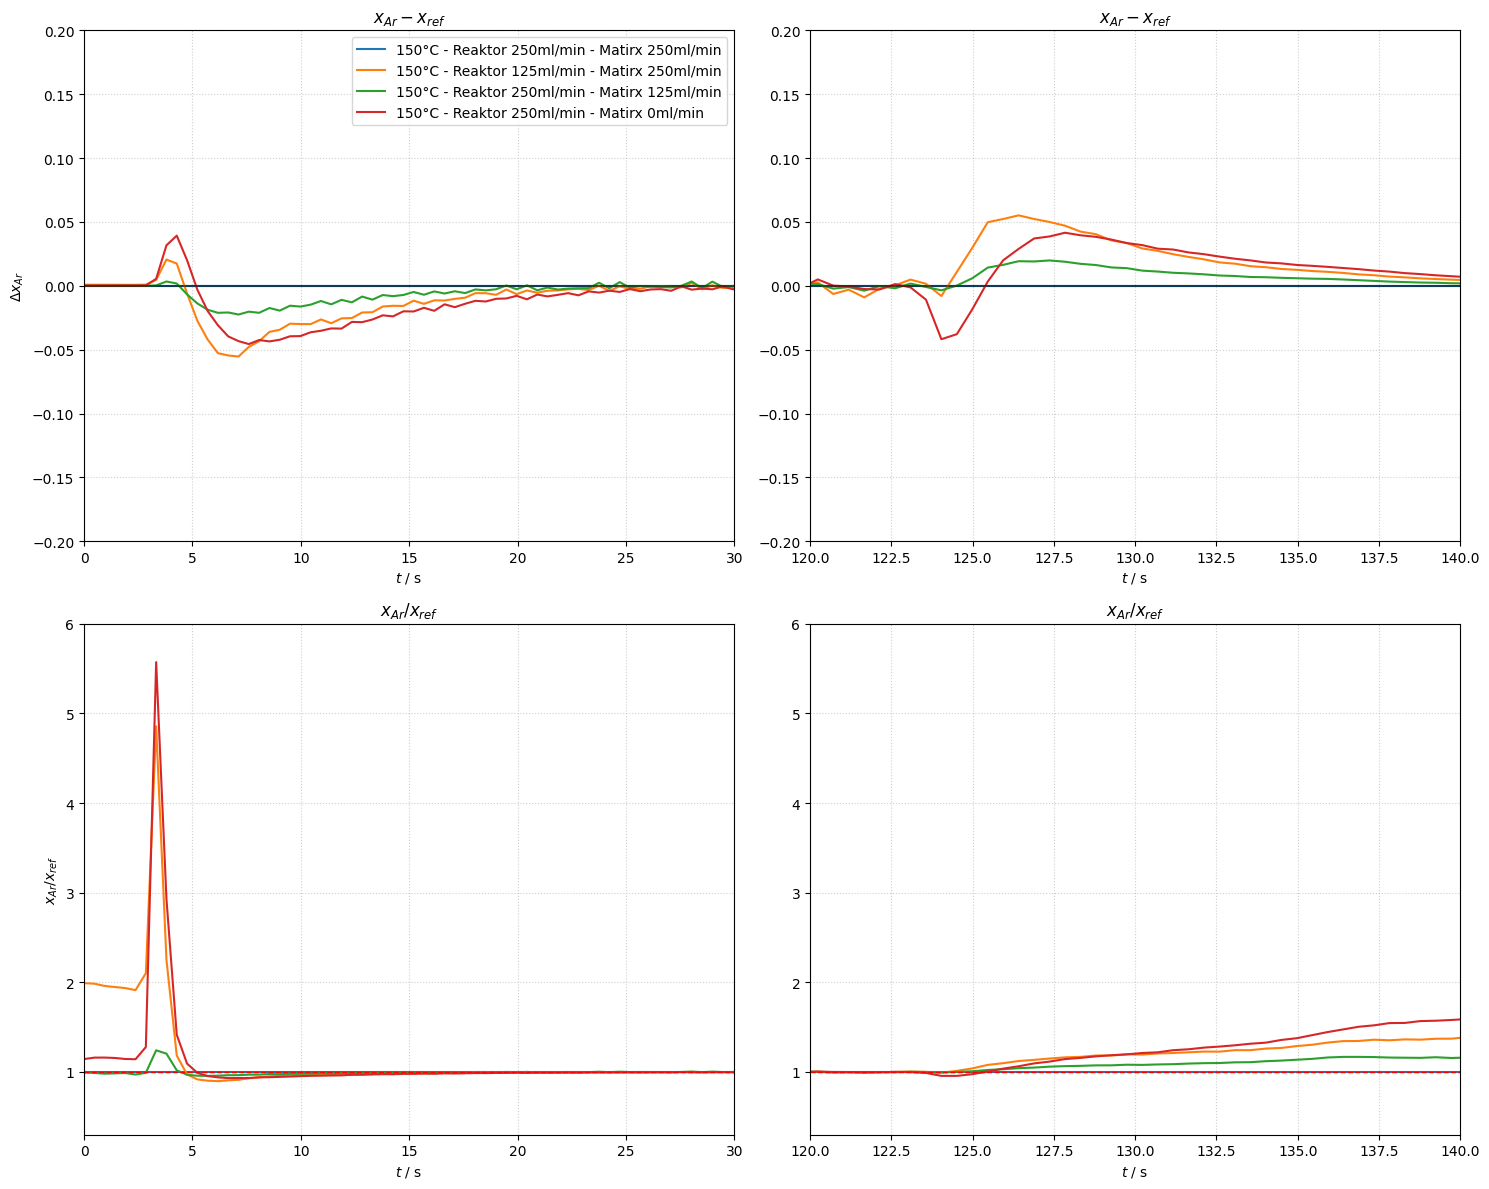

In [6]:
dataset_ptks = [data_ptk1, 
                data_ptk2, 
                data_ptk3, 
                data_ptk4
]

titles = [
    "150°C - Reaktor 250ml/min - Matirx 250ml/min", 
    "150°C - Reaktor 125ml/min - Matirx 250ml/min",
    "150°C - Reaktor 250ml/min - Matirx 125ml/min",
    "150°C - Reaktor 250ml/min - Matirx 0ml/min"
]

def get_x_norm(data):
    t = data['time_delta']
    n_matrix = data['n_dot']
    n_total = np.sum(n_matrix, axis=0)
    x_Ar = np.divide(n_matrix[0], n_total, out=np.zeros_like(n_matrix[0]), where=n_total!=0)
    mask_ss = (t >= 80) & (t <= 100)
    return x_Ar / np.mean(x_Ar[mask_ss])

x_ref = get_x_norm(data_ptk1)
t_ref = data_ptk1['time_delta']

fig, axs = plt.subplots(2, 2, figsize=(15, 12))
((ax_diff_up, ax_diff_down), (ax_ratio_up, ax_ratio_down)) = axs

for data, title in zip(dataset_ptks, titles):
    x_curr = get_x_norm(data)
    t_curr = data['time_delta']
    
    x_diff = x_curr - x_ref
    ratio = np.divide(x_curr, x_ref, out=np.ones_like(x_curr), where=x_ref!=0)

    ax_diff_up.plot(t_curr, x_diff, label=title)
    ax_diff_down.plot(t_curr, x_diff)
    ax_ratio_up.plot(t_curr, ratio)
    ax_ratio_down.plot(t_curr, ratio)


ax_diff_up.set_title('$x_{Ar} - x_{ref}$', fontweight='bold')
ax_diff_up.set_xlim(0, 30)
ax_diff_up.set_ylim(-0.2, 0.2)
ax_diff_up.axhline(0, color='black', linewidth=1.5, alpha=0.5)

ax_diff_down.set_title('$x_{Ar} - x_{ref}$', fontweight='bold')
ax_diff_down.set_xlim(120, 140)
ax_diff_down.set_ylim(-0.2, 0.2)
ax_diff_down.axhline(0, color='black', linewidth=1.5, alpha=0.5)

ax_ratio_up.set_title('$x_{Ar} / x_{ref}$', fontweight='bold')
ax_ratio_up.set_xlim(0, 30)
ax_ratio_up.set_ylim(0.3, 6)
ax_ratio_up.axhline(1, color='red', linestyle='--', linewidth=1)

ax_ratio_down.set_title('$x_{Ar} / x_{ref}$', fontweight='bold')
ax_ratio_down.set_xlim(120, 140)
ax_ratio_down.set_ylim(0.3, 6)
ax_ratio_down.axhline(1, color='red', linestyle='--', linewidth=1)

for ax in axs.flat:
    ax.grid(True, which='both', linestyle=':', alpha=0.6)
    ax.set_xlabel('$t$ / s')

ax_diff_up.set_ylabel('$\Delta x_{Ar}$')
ax_ratio_up.set_ylabel('$x_{Ar} / x_{ref}$')

# Legende
ax_diff_up.legend(loc='upper right')

plt.tight_layout()
plt.show()

# Temperatur Variation

## gesamte Temperaturvariation

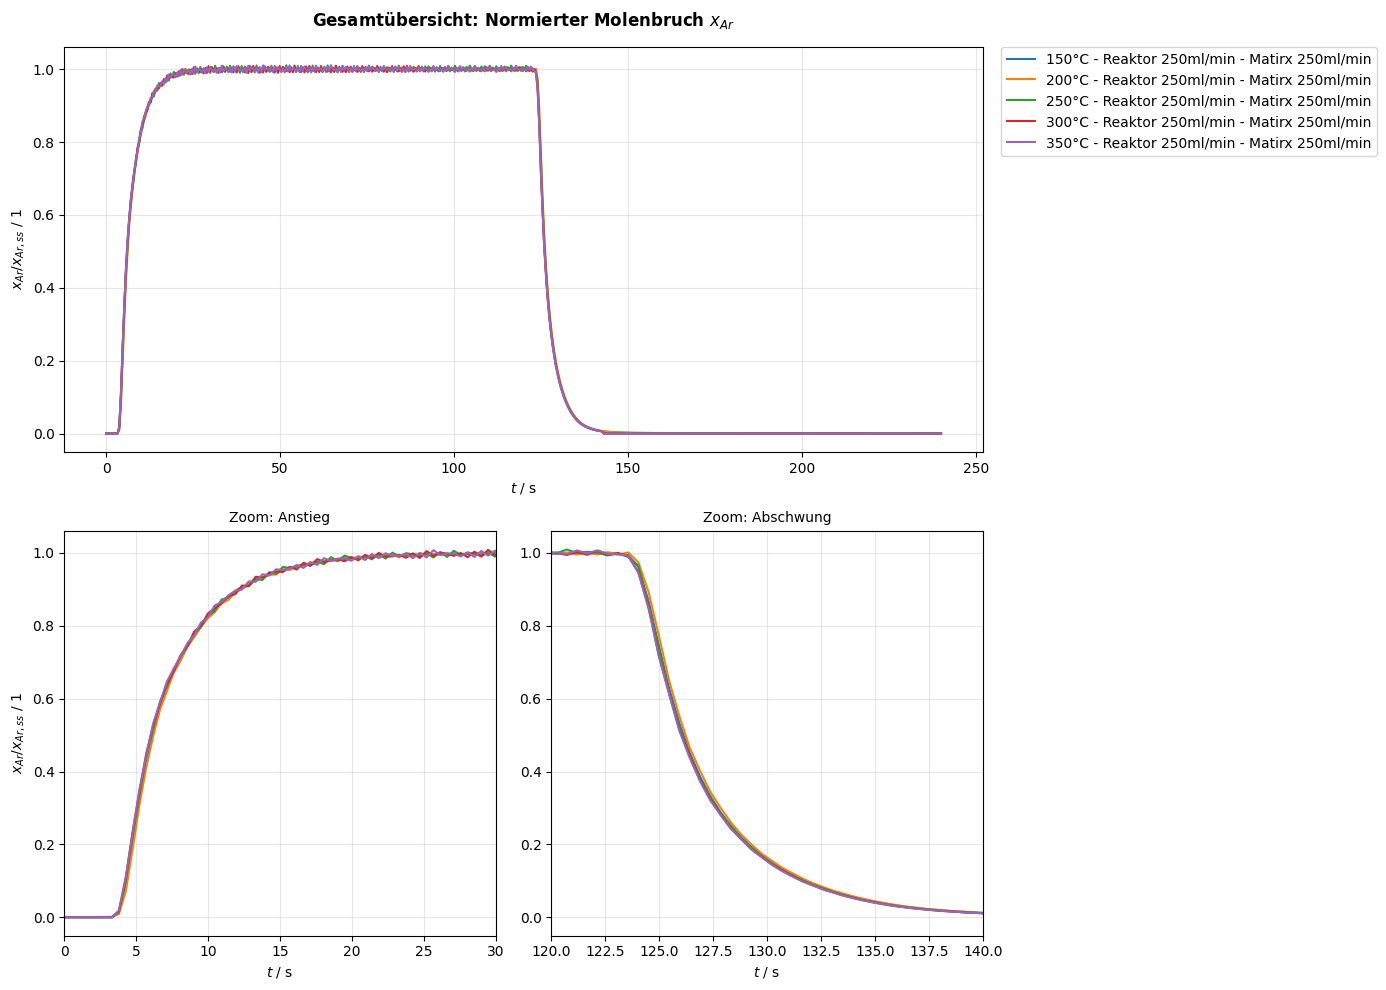

In [7]:
dataset_ptks = [data_ptk1,  
                data_ptk5, 
                data_ptk6, 
                data_ptk7, 
                data_ptk8]

titles = [
    "150°C - Reaktor 250ml/min - Matirx 250ml/min", 
    "200°C - Reaktor 250ml/min - Matirx 250ml/min",
    "250°C - Reaktor 250ml/min - Matirx 250ml/min",
    "300°C - Reaktor 250ml/min - Matirx 250ml/min",
    "350°C - Reaktor 250ml/min - Matirx 250ml/min"
]

fig = plt.figure(figsize=(14, 10))

ax1 = plt.subplot2grid((2, 2), (0, 0), colspan=2)

ax2 = plt.subplot2grid((2, 2), (1, 0)) 
ax3 = plt.subplot2grid((2, 2), (1, 1)) 


for data, title in zip(dataset_ptks, titles):
    t = data['time_delta']
    n_matrix = data['n_dot']
    
    n_total = np.sum(n_matrix, axis=0)
    x_Ar = np.divide(n_matrix[0], n_total, out=np.zeros_like(n_matrix[0]), where=n_total!=0)
    
    mask_ss = (t >= 80) & (t <= 100)
    x_Ar_ss_val = np.mean(x_Ar[mask_ss])
    x_Ar_normed = x_Ar / x_Ar_ss_val 

    ax1.plot(t, x_Ar_normed, label=title)
    ax2.plot(t, x_Ar_normed)
    ax3.plot(t, x_Ar_normed)

ax1.set_title('Gesamtübersicht: Normierter Molenbruch $x_{Ar}$', fontweight='bold', pad=15)
ax1.set_ylabel('$x_{Ar} / x_{Ar,ss}$ / 1')
ax1.set_xlabel('$t$ / s')
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

ax2.set_title('Zoom: Anstieg', fontsize=10)
ax2.set_xlim(0, 30)
ax2.set_xlabel('$t$ / s')
ax2.set_ylabel('$x_{Ar} / x_{Ar,ss}$ / 1')
ax2.grid(True, alpha=0.3)

ax3.set_title('Zoom: Abschwung', fontsize=10)
ax3.set_xlim(120, 140)
ax3.set_xlabel('$t$ / s')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Temperaturvariation mit Referenz

<>:66: SyntaxWarning: invalid escape sequence '\D'
<>:66: SyntaxWarning: invalid escape sequence '\D'
C:\Users\admin\AppData\Local\Temp\ipykernel_18116\1752471304.py:66: SyntaxWarning: invalid escape sequence '\D'
  ax_diff_up.set_ylabel('$\Delta x_{Ar}$')


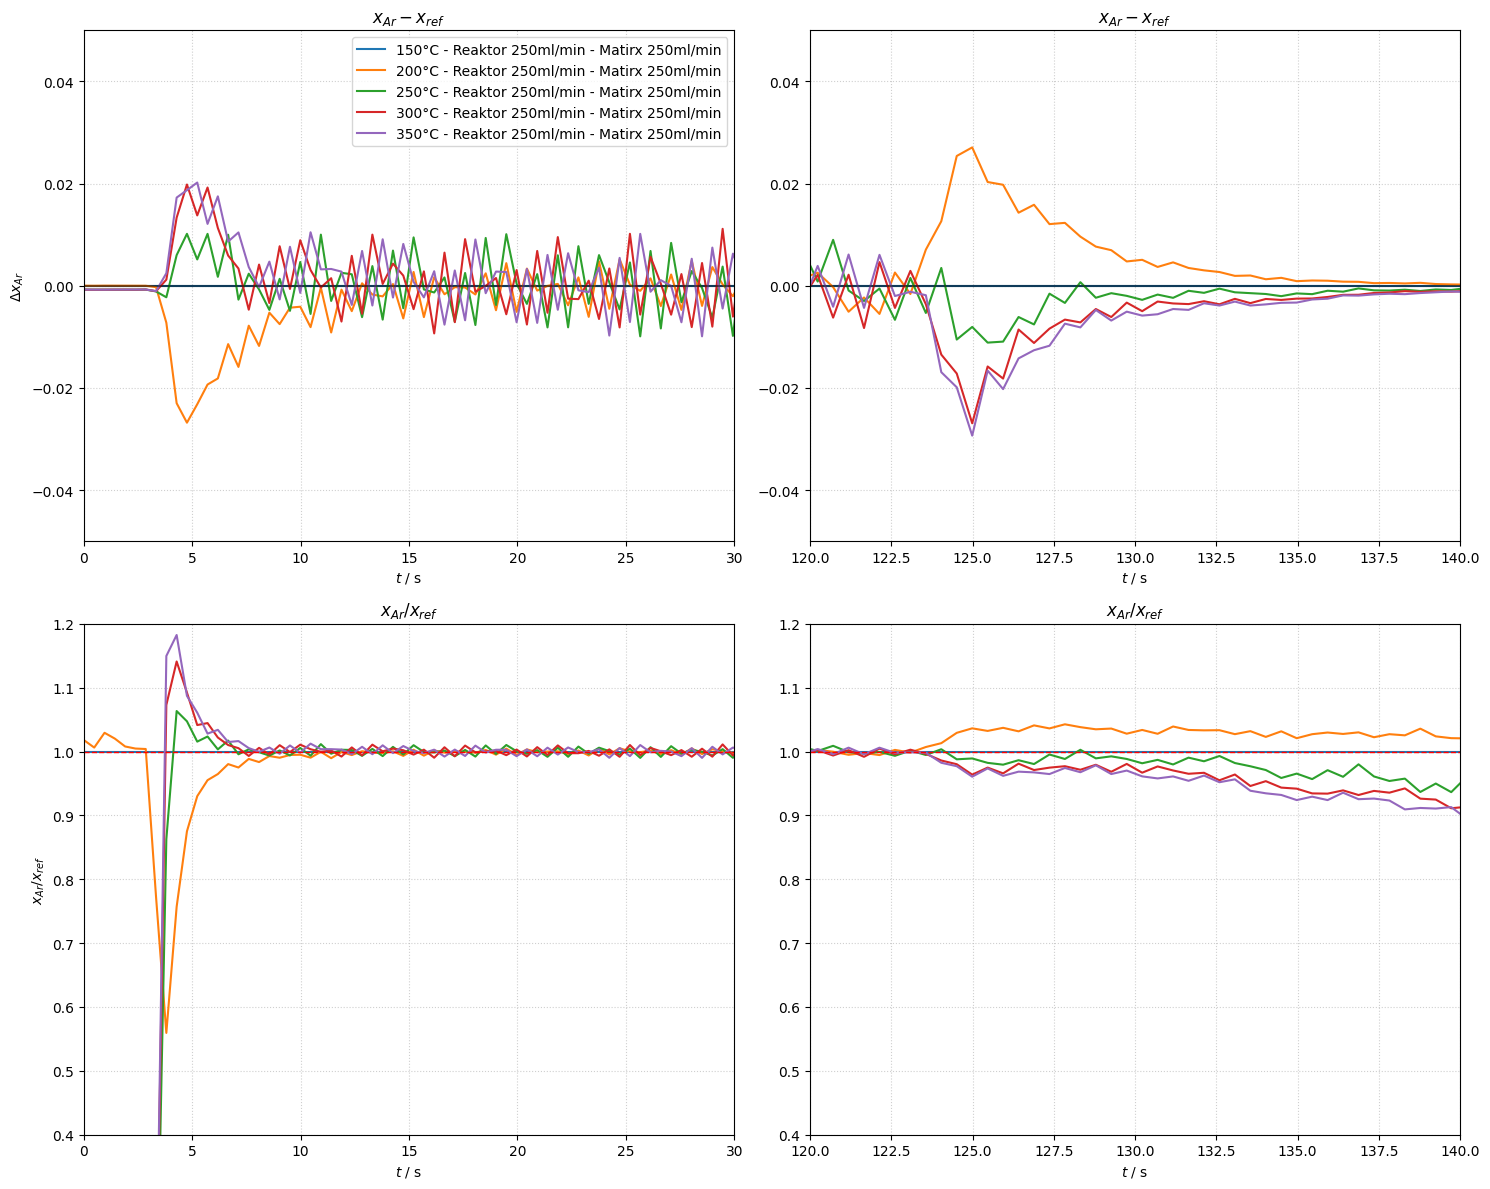

In [8]:
dataset_ptks = [data_ptk1,  
                data_ptk5, 
                data_ptk6, 
                data_ptk7, 
                data_ptk8]

titles = [
    "150°C - Reaktor 250ml/min - Matirx 250ml/min", 
    "200°C - Reaktor 250ml/min - Matirx 250ml/min",
    "250°C - Reaktor 250ml/min - Matirx 250ml/min",
    "300°C - Reaktor 250ml/min - Matirx 250ml/min",
    "350°C - Reaktor 250ml/min - Matirx 250ml/min"
]

def get_x_norm(data):
    t = data['time_delta']
    n_matrix = data['n_dot']
    n_total = np.sum(n_matrix, axis=0)
    x_Ar = np.divide(n_matrix[0], n_total, out=np.zeros_like(n_matrix[0]), where=n_total!=0)
    mask_ss = (t >= 80) & (t <= 100)
    return x_Ar / np.mean(x_Ar[mask_ss])

x_ref = get_x_norm(data_ptk1)
t_ref = data_ptk1['time_delta']

fig, axs = plt.subplots(2, 2, figsize=(15, 12))
((ax_diff_up, ax_diff_down), (ax_ratio_up, ax_ratio_down)) = axs

for data, title in zip(dataset_ptks, titles):
    x_curr = get_x_norm(data)
    t_curr = data['time_delta']
    
    x_diff = x_curr - x_ref
    ratio = np.divide(x_curr, x_ref, out=np.ones_like(x_curr), where=x_ref!=0)

    ax_diff_up.plot(t_curr, x_diff, label=title)
    ax_diff_down.plot(t_curr, x_diff)
    ax_ratio_up.plot(t_curr, ratio)
    ax_ratio_down.plot(t_curr, ratio)


ax_diff_up.set_title('$x_{Ar} - x_{ref}$', fontweight='bold')
ax_diff_up.set_xlim(0, 30)
ax_diff_up.set_ylim(-0.05, 0.05)
ax_diff_up.axhline(0, color='black', linewidth=1.5, alpha=0.5)

ax_diff_down.set_title('$x_{Ar} - x_{ref}$', fontweight='bold')
ax_diff_down.set_xlim(120, 140)
ax_diff_down.set_ylim(-0.05, 0.05)
ax_diff_down.axhline(0, color='black', linewidth=1.5, alpha=0.5)

ax_ratio_up.set_title('$x_{Ar} / x_{ref}$', fontweight='bold')
ax_ratio_up.set_xlim(0, 30)
ax_ratio_up.set_ylim(0.4, 1.2)
ax_ratio_up.axhline(1, color='red', linestyle='--', linewidth=1)

ax_ratio_down.set_title('$x_{Ar} / x_{ref}$', fontweight='bold')
ax_ratio_down.set_xlim(120, 140)
ax_ratio_down.set_ylim(0.4, 1.2)
ax_ratio_down.axhline(1, color='red', linestyle='--', linewidth=1)

for ax in axs.flat:
    ax.grid(True, which='both', linestyle=':', alpha=0.6)
    ax.set_xlabel('$t$ / s')

ax_diff_up.set_ylabel('$\Delta x_{Ar}$')
ax_ratio_up.set_ylabel('$x_{Ar} / x_{ref}$')

# Legende
ax_diff_up.legend(loc='upper right')

plt.tight_layout()
plt.show()